# Hwang et al. 2022 — PDAC
## 04 · EMT-TF expression
Unconditional final step (linear geometry: Gate 1 GO, Gate 2 GO non-branching, Gate 3 NA -> the branching-only correlation/modules notebooks are not produced; expression is renumbered to 04). Score a broad EMT-TF panel (Snail/Zeb/Twist **plus** FOXC/PRRX families) gated on detectable expression, and overlay the root-end and terminus-end factors as a categorical thresholded-expresser layer on the grey manifold.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

Load `processed.h5ad` (per §6 the expression step reads the processed object); carry over the house linear layout and pseudotime from `signatures.h5ad`.

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sig = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata = adata[sig.obs_names].copy()
adata.obsm['X_umap_lin'] = sig.obsm['X_umap_lin']; adata.obs['t'] = sig.obs['t'].values
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 64006 | pseudotime range 0.0 -> 11.23


**Derive the EMT-TF pair.** For each detectably-expressed TF, mean expression in the early (root) vs late (terminus) pseudotime tercile and Spearman rho vs pseudotime; take the most root-biased and most terminus-biased factors among those expressed in >3% of cells.

In [6]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']; late_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB1      0.157       0.254      0.139    -0.127    EARLY(root)
 SNAI2      0.021       0.039      0.015    -0.085    EARLY(root)
 FOXC1      0.036       0.054      0.027    -0.082    EARLY(root)
 PRRX2      0.042       0.057      0.029    -0.077    EARLY(root)
 FOXC2      0.004       0.005      0.003    -0.026    EARLY(root)
 SNAI1      0.001       0.001      0.000    -0.019    EARLY(root)
TWIST2      0.001       0.002      0.001    -0.014    EARLY(root)
TWIST1      0.001       0.002      0.002    -0.013 LATE(terminus)
 PRRX1      0.021       0.023      0.025    -0.013 LATE(terminus)
  ZEB2      0.020       0.022      0.037     0.005 LATE(terminus)

derived pair: ZEB1 (early/root) <-> PRRX2 (late/terminus)


**Figure — `expression.pdf`.** Categorical overlay: cells above the upper-quartile-among-expressers threshold for each factor, coloured on the grey manifold (not a continuous colormap). House `(3.5,1.5)` strip, marker size matched to the other panels.

overlay thresholds (upper quartile among expressers): {'ZEB1': 1.505, 'PRRX2': 1.238} | cells shown: {'ZEB1': 2510, 'PRRX2': 675}
ZEB1: 15.7% expressing; 2510 shown; mean pseudotime of shown = 0.58 (all = 0.58)
PRRX2: 4.2% expressing; 675 shown; mean pseudotime of shown = 0.60 (all = 0.58)
saved expression.pdf


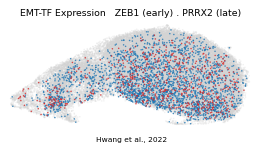

In [8]:
xl = adata.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf,late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Hwang et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')